# 03 - Trading simulation

1. **Vectorised simulations** (course approach) for every model: `sim1` probability threshold, `sim2`
   top-5 per day, `sim3` top-5 only in bull markets, `sim4` long-short (long top-5 / short bottom-5).
2. **Exact day-by-day simulation** with $100k, reinvestment of gains, 1/20 of the equity invested
   per day, stop-loss / take-profit, position size by probability and a market-regime filter.
   The strategy is **chosen on the validation period (2019-2021)** and evaluated once on **test (2022-2026)**.
3. Profitability vs benchmarks (ILF, EWZ, S&P 500): CAGR, Sharpe, max drawdown, rolling returns.

All returns are in USD and include 0.1% fees per side.

In [1]:
import sys
sys.path.insert(0, "..")
import itertools
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import config as cfg
from scripts.simulate import (add_vector_sims, benchmark_equity, exact_simulation, performance,
                              rolling_returns, summarize_vector_sims)

pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")
IMG = cfg.ROOT / "images"

pred = pd.read_parquet(cfg.PROCESSED_DIR / "predictions.parquet")
market = pd.read_parquet(cfg.RAW_DIR / "market.parquet")
PREDS = [c for c in pred.columns if c.startswith("pred_")]
val = pred[pred["split"] == "validation"].copy()
test = pred[pred["split"] == "test"].copy()
print(val["Date"].min().date(), val["Date"].max().date(), "|", test["Date"].min().date(), test["Date"].max().date())

2019-01-02 2021-12-01 | 2022-01-03 2026-09-23


## 1. Vectorised simulations (test period)

In [2]:
for p in PREDS:
    test = add_vector_sims(test, p, threshold=0.55, k=5)
vec = summarize_vector_sims(test, PREDS)
vec.sort_values("cagr", ascending=False).round(3)

,strategy,prediction,trades,trades_per_day,win_rate,gross_rev,fees,net_rev,capital,cagr
5,sim2,pred_rf,6110,5.00,0.591,15505.466797,-1237.505981,14267.961914,10000.0,1.207
13,sim2,pred_ensemble,6110,5.00,0.571,13324.425781,-1235.323975,12089.101562,10000.0,1.183
9,sim2,pred_xgb,6110,5.00,0.556,11793.302734,-1233.792969,10559.509766,10000.0,1.165
4,sim1,pred_rf,16274,13.32,0.573,36138.519531,-3290.937988,32847.578125,36000.0,1.147
1,sim2,pred_dt,6110,5.00,0.533,9317.111328,-1231.317017,8085.793945,10000.0,1.134
6,sim3,pred_rf,4046,3.31,0.571,8113.358887,-817.312988,7296.045898,10000.0,1.123
8,sim1,pred_xgb,15369,12.58,0.553,29837.410156,-3103.637939,26733.773438,38000.0,1.119
12,sim1,pred_ensemble,26707,21.86,0.552,46551.390625,-5387.952148,41163.437500,60000.0,1.117
0,sim1,pred_dt,53522,43.80,0.533,80123.750000,-10784.523438,69339.226562,106000.0,1.113
14,sim3,pred_ensemble,3782,3.09,0.555,6237.644043,-762.638000,5475.005859,10000.0,1.097


- **sim2 (top-5 per day)** is the most efficient use of capital: with RandomForest it earns $14.3k net on
  $10k of capital in 4.7 years (approx. CAGR 1.207) with a 59% win rate.
- **sim1 (p > 0.55)** trades 2-9 times more and needs more capital, so its CAGR is lower.
- **sim3 (bull markets only)** reduces trades by a third but also the profit: the model's picks also work
  in bear regimes.
- **sim4 (long-short)** is market neutral (it earns the spread between the best and the worst ranked stocks):
  approx. CAGR 1.090 with RandomForest, with no exposure to the direction of the market.
- The single DecisionTree is the weakest model in every strategy.

## 2. Exact simulation: choose the strategy on validation (2019-2021)

In [3]:
rf_val = market["us3m"].reindex(val["Date"].unique()).mean() / 100
rf_test = market["us3m"].reindex(test["Date"].unique()).mean() / 100
grid = list(itertools.product(["pred_rf", "pred_xgb", "pred_ensemble"], [5, 10],
                              [(None, None), (0.10, None), (0.15, 0.30)],
                              [False, True], [False, True]))
rows = []
for p, k, (sl, tp), size, regime in grid:
    eq, tr = exact_simulation(val, p, k=k, threshold=0.5, stop_loss=sl, take_profit=tp,
                              size_by_prob=size, regime_filter=regime)
    rows.append({"prediction": p, "k": k, "stop_loss": sl, "take_profit": tp, "size_by_prob": size,
                 "regime_filter": regime, "trades": len(tr), **performance(eq, rf_val)})
val_grid = pd.DataFrame(rows).sort_values("sharpe", ascending=False)
val_grid.head(15).round(3)

,prediction,k,stop_loss,take_profit,size_by_prob,regime_filter,trades,cagr,annual_vol,sharpe,max_drawdown,calmar,total_return
30,pred_xgb,5,0.10,NaN,True,False,3684,1.133,0.195,0.679,-0.269,0.495,0.438
6,pred_rf,5,0.10,NaN,True,False,3679,1.132,0.197,0.669,-0.265,0.498,0.435
28,pred_xgb,5,0.10,NaN,False,False,3684,1.123,0.194,0.637,-0.270,0.455,0.402
4,pred_rf,5,0.10,NaN,False,False,3679,1.117,0.197,0.605,-0.266,0.441,0.381
18,pred_rf,10,0.10,NaN,True,False,5603,1.113,0.189,0.602,-0.265,0.426,0.365
54,pred_ensemble,5,0.10,NaN,True,False,3692,1.108,0.196,0.568,-0.283,0.383,0.350
66,pred_ensemble,10,0.10,NaN,True,False,5622,1.096,0.190,0.520,-0.274,0.349,0.304
34,pred_xgb,5,0.15,0.3,True,False,3647,1.097,0.207,0.501,-0.332,0.293,0.310
42,pred_xgb,10,0.10,NaN,True,False,5660,1.090,0.189,0.495,-0.276,0.325,0.284
10,pred_rf,5,0.15,0.3,True,False,3645,1.096,0.209,0.495,-0.325,0.296,0.307


On validation (2019-2021, including the COVID crash) the **10% stop-loss** is in every top configuration, and
**probability-weighted sizing** helps slightly. The market-regime filter never makes the top: it removes
good trades after crashes, when the rebound starts.

In [4]:
best = val_grid.iloc[0]
STRATEGY = {"prediction": best.prediction, "k": int(best.k), "threshold": 0.5,
            "stop_loss": None if pd.isna(best.stop_loss) else float(best.stop_loss),
            "take_profit": None if pd.isna(best.take_profit) else float(best.take_profit),
            "size_by_prob": bool(best.size_by_prob), "regime_filter": bool(best.regime_filter)}
(cfg.OUTPUT_DIR / "selected_strategy.json").write_text(json.dumps(STRATEGY, indent=2))
STRATEGY

{'prediction': 'pred_xgb',
 'k': 5,
 'threshold': 0.5,
 'stop_loss': 0.1,
 'take_profit': None,
 'size_by_prob': True,
 'regime_filter': False}

## 3. Test period (2022-2026): the selected strategy vs benchmarks

In [5]:
def run(df, s):
    return exact_simulation(df, s["prediction"], k=s["k"], threshold=s["threshold"], stop_loss=s["stop_loss"],
                            take_profit=s["take_profit"], size_by_prob=s["size_by_prob"],
                            regime_filter=s["regime_filter"])

equity, trades = run(test, STRATEGY)
baseline = {**STRATEGY, "stop_loss": None, "take_profit": None, "size_by_prob": False, "regime_filter": False}
equity_base, trades_base = run(test, baseline)
bench = benchmark_equity(market, equity.index)
curves = pd.concat([equity.rename("Selected strategy"), equity_base.rename(f"Top-{STRATEGY['k']} (no rules)"), bench], axis=1)
summary = pd.DataFrame({c: performance(curves[c], rf_test) for c in curves}).T
summary.round(3)

,cagr,annual_vol,sharpe,max_drawdown,calmar,total_return
Selected strategy,1.179,0.149,0.885,-0.224,0.800,1.174
Top-5 (no rules),1.198,0.166,0.905,-0.226,0.879,1.347
ILF (Latin America 40),1.161,0.226,0.581,-0.297,0.540,1.019
EWZ (Brazil),1.143,0.266,0.472,-0.322,0.442,0.875
S&P 500,1.106,0.169,0.429,-0.254,0.416,0.607


On the test period the selected strategy (XGBoost top-5, 10% stop-loss, size by probability) returns
**CAGR 17.9% vs 16.1% for ILF, 14.3% for EWZ and 10.6% for the S&P 500**, with lower volatility (14.9% vs 22.6%),
a better Sharpe ratio (0.89 vs 0.58) and a smaller max drawdown (-22.4% vs -29.7%).
The plain top-5 without rules made slightly more (CAGR 19.8%) with more volatility: on this period the
stop-loss costs some return and buys a smoother equity curve.

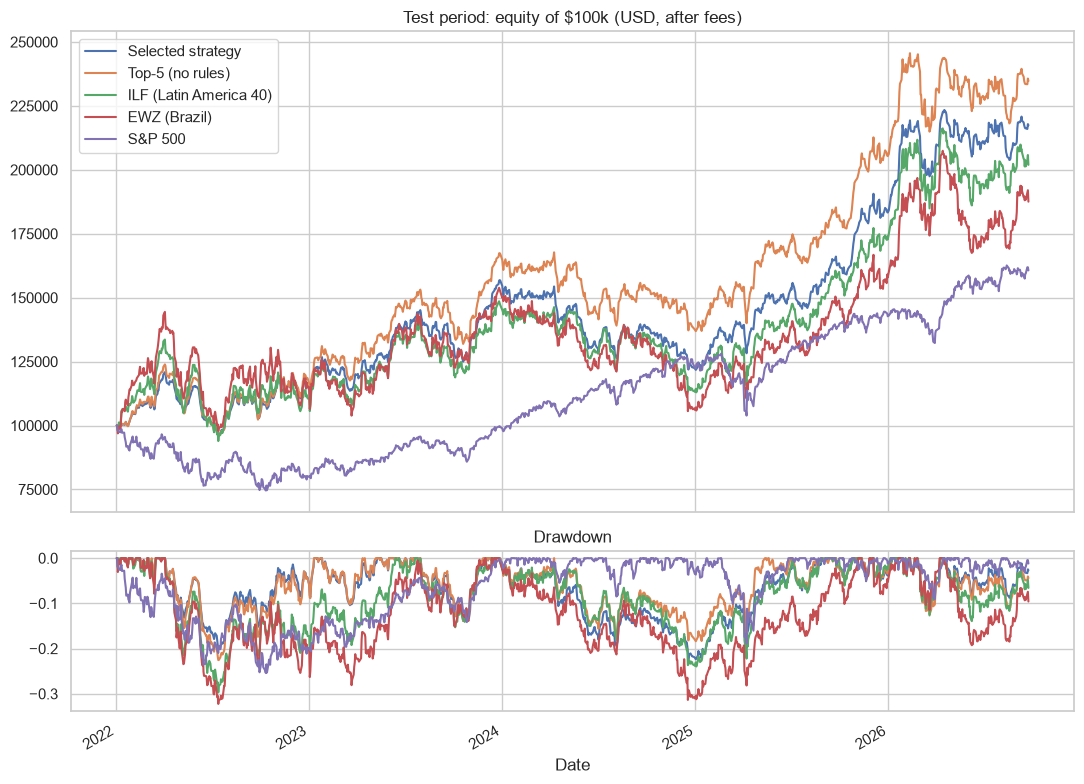

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
curves.plot(ax=axes[0], title="Test period: equity of $100k (USD, after fees)")
(curves / curves.cummax() - 1).plot(ax=axes[1], legend=False, title="Drawdown")
plt.tight_layout(); plt.savefig(IMG / "sim_equity_test.png", dpi=110); plt.show()

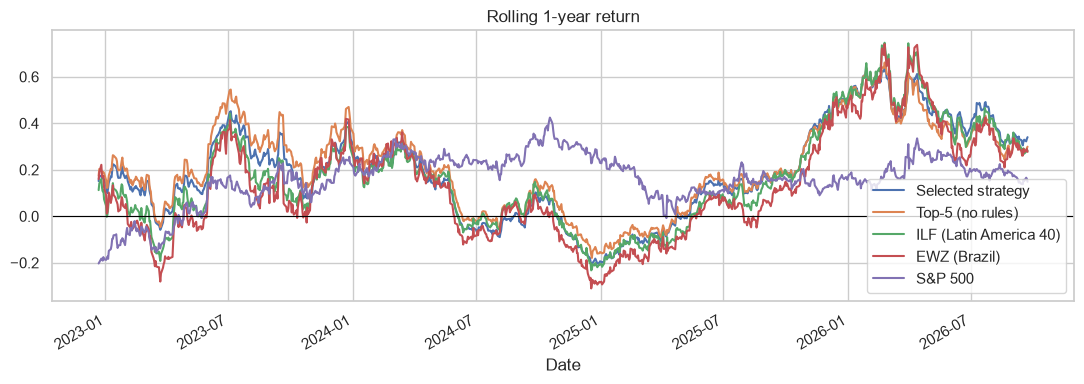

share of days the strategy's 1y return beats ILF: 0.696


In [7]:
roll = pd.concat({c: rolling_returns(curves[c]) for c in curves}, axis=1)
ax = roll.plot(figsize=(11, 4), title="Rolling 1-year return")
ax.axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.savefig(IMG / "sim_rolling.png", dpi=110); plt.show()
print("share of days the strategy's 1y return beats ILF:",
      round((roll["Selected strategy"] > roll["ILF (Latin America 40)"]).loc[roll["Selected strategy"].notna()].mean(), 3))

The 1-year rolling return of the strategy is above ILF ~70% of the days.

### All validation-grid strategies on test (to check the choice is not a lucky one)

In [8]:
rows = []
for r in val_grid.head(10).itertuples():
    s = {"prediction": r.prediction, "k": int(r.k), "threshold": 0.5,
         "stop_loss": None if pd.isna(r.stop_loss) else r.stop_loss,
         "take_profit": None if pd.isna(r.take_profit) else r.take_profit,
         "size_by_prob": r.size_by_prob, "regime_filter": r.regime_filter}
    eq, _ = run(test, s)
    rows.append({**s, "val_sharpe": r.sharpe, **{f"test_{k}": v for k, v in performance(eq, rf_test).items()}})
pd.DataFrame(rows).round(3)

,prediction,k,threshold,stop_loss,take_profit,size_by_prob,regime_filter,val_sharpe,test_cagr,test_annual_vol,test_sharpe,test_max_drawdown,test_calmar,test_total_return
0,pred_xgb,5,0.5,0.10,NaN,True,False,0.679,1.179,0.149,0.885,-0.224,0.800,1.174
1,pred_rf,5,0.5,0.10,NaN,True,False,0.669,1.190,0.154,0.924,-0.221,0.862,1.276
2,pred_xgb,5,0.5,0.10,NaN,False,False,0.637,1.176,0.150,0.866,-0.206,0.854,1.153
3,pred_rf,5,0.5,0.10,NaN,False,False,0.605,1.182,0.155,0.871,-0.227,0.800,1.200
4,pred_rf,10,0.5,0.10,NaN,True,False,0.602,1.184,0.155,0.885,-0.215,0.858,1.222
5,pred_ensemble,5,0.5,0.10,NaN,True,False,0.568,1.178,0.153,0.864,-0.213,0.838,1.169
6,pred_ensemble,10,0.5,0.10,NaN,True,False,0.520,1.154,0.151,0.734,-0.239,0.644,0.963
7,pred_xgb,5,0.5,0.15,0.3,True,False,0.501,1.200,0.159,0.952,-0.227,0.884,1.367
8,pred_xgb,10,0.5,0.10,NaN,True,False,0.495,1.152,0.151,0.726,-0.221,0.688,0.951
9,pred_rf,5,0.5,0.15,0.3,True,False,0.495,1.187,0.162,0.868,-0.235,0.796,1.250


All of the 10 best validation configurations beat ILF on test (CAGR 1.15-1.20, Sharpe 0.73-0.95): the result
does not depend on one lucky choice.

## 4. Trades analysis (selected strategy, test)

In [9]:
trades["year"] = trades["exit_date"].dt.year
print(trades.groupby("reason").agg(trades=("pnl", "size"), avg_return=("return", "mean"), pnl=("pnl", "sum")).round(3))
print(trades.groupby("market").agg(trades=("pnl", "size"), win_rate=("return", lambda r: (r > 0).mean()),
                                   avg_return=("return", "mean"), pnl=("pnl", "sum")).round(3))
trades.groupby("year").agg(trades=("pnl", "size"), win_rate=("return", lambda r: (r > 0).mean()),
                           avg_return=("return", "mean"), pnl=("pnl", "sum")).round(3)

           trades  avg_return           pnl
reason                                     
stop_loss     995      -0.117 -171464.78125
time         4811       0.042  286482.93750
        trades  win_rate  avg_return           pnl
market                                            
AN         257     0.560       0.017   6762.583984
AR         415     0.533       0.045  23603.718750
BR        3039     0.515       0.011  43017.867188
CL         671     0.534       0.014  15686.691406
MX        1424     0.550       0.014  25947.281250


,trades,win_rate,avg_return,pnl
year,,,,
2022,1104,0.505,0.013,12757.183594
2023,1220,0.582,0.026,37339.945312
2024,1297,0.405,-0.012,-25817.259766
2025,1256,0.616,0.031,59140.882812
2026,929,0.543,0.018,31597.392578


In [10]:
trades.groupby("ticker").agg(trades=("pnl", "size"), pnl=("pnl", "sum")).sort_values("pnl").iloc[np.r_[0:5, -5:0]].round(0)

,trades,pnl
ticker,,
VAPORES.SN,19,-1739.0
PGMN3.SA,7,-1220.0
GLOB,20,-1186.0
GGPS3.SA,21,-1115.0
DXCO3.SA,34,-1060.0
JHSF3.SA,19,2360.0
VIST,33,2836.0
CXSE3.SA,43,3334.0
BMA,32,3578.0


**Insights and ideas for improvement**
- Stop-losses fire in ~17% of the trades (-11.7% average) and the time exits make +4.2% on average: the edge
  comes from holding winners for the full 20 days.
- Every market is profitable; Argentine ADRs have the highest average return per trade (+4.5%) and Brazil
  the lowest (+1.1%, but half of all trades). A per-market model or more weight on non-Brazilian picks
  could help.
- 2024 was a losing year (win rate 40.5%), the only one in the test period. Checking which features
  changed behaviour that year (e.g. a currency-regime filter on the BRL trend) is a next step.
- Utilities and Financials make more than half of the top-5 picks; limiting the number of positions per
  sector would diversify the portfolio.